# 06 - Weighted interval sampling

The authors suggest that ExtraTrees should draw features from larger intervals more often (paper, Section 4.2.1,
left for future work). scikit-learn's ExtraTrees has no feature weights, so `improvedQuant/weighted/run.py` gives it the
features of the larger intervals several times: a feature with 3 copies is drawn about 3 times as often. The levels are
compared within each view: a level with fewer features than the
largest level of its view gets round copies, e.g. a series of 286 points at the authors' setting: the
whole series x3, the halves x2, the smaller intervals x1, in every view. Three classifiers, all scikit-learn's
ExtraTrees with QUANT's settings, on the same QUANT features of every run:

| Classifier | What it is |
|---|---|
| **QUANT**, `extratrees` | the authors' classifier: QUANT's features, 10% tried per split |
| **control**, `extratrees-k` | QUANT's features, as many tried per split as with copies (the copies add columns, so ExtraTrees tries more) |
| **copies**, `extratrees-dup` | the larger intervals' features copied, 10% of the columns tried per split |

**copies - control** is the effect of the weighting; **copies - QUANT** is the whole change against the authors'
method. Settings: `d6v4` is the authors' (depth 6, m / 4 quantiles per interval); the others change the depth (8) or the
quantiles (m / 16).

**Two questions**, from the paper's Figure 8 (with few quantiles per interval, accuracy falls beyond depth 6):
1. **Deeper:** do the copies stop the loss of accuracy at depth 8?
2. **Cheaper:** does the cheap setting (m / 16) with copies reach the accuracy of QUANT's default?

**The files:** `results/w-{setting}_ucr142.csv`, 142 datasets x 30 resamples. The analysis (sections 1 to 6)
reads only `results/`, not `data/`. Per dataset: the mean accuracy over its resamples; between two classifiers:
better / equal / worse datasets and a Wilcoxon signed-rank test over the datasets.

## 0. Run the full benchmark (optional, about 5-6 hours)

The analysis below reads the results files; this section makes them for the full benchmark (142 datasets x 30
resamples, all four settings).
It runs the four settings with `improvedQuant/weighted/run.py`, one results file each
(`results/w-d{depth}v{div}_ucr142.csv`), and shows the progress.

A run can be stopped (the stop button of the notebook) and continued: running the cell again skips the runs already in
the file.

In [1]:
import subprocess
import sys
import time
from pathlib import Path
from common import REPO, RESULTS_DIR

RUN = False                      
DATASETS = REPO / "original" / "code" / "ucr142.txt"       
RESAMPLES = 30
RUN_SETTINGS = [(6, 4), (6, 16), (8, 4), (8, 16)]           
DATA_TS, DATA_INDICES = REPO / "data" / "ts", REPO / "data" / "indices"
LOGS = REPO / "data" / "logs"

In [2]:
# == one setting of run.py, with its progress =========================================================================
def run_setting(depth, div, datasets, resamples, out, classifiers=("all",)):
    cmd = [sys.executable, str(REPO / "improvedQuant" / "weighted" / "run.py"), "-i", str(DATA_TS), "-p", str(DATA_INDICES),
           "-d", str(datasets), "-r", str(resamples), "-c", *classifiers, "-m", str(depth), "-v", str(div), "-o", str(out)]
    if sys.platform == "darwin":
        cmd = ["caffeinate", "-i", *cmd]          
    n_classifiers = 3 if "all" in classifiers else len(classifiers)
    expected = len(Path(datasets).read_text().split()) * resamples * n_classifiers
    rows = lambda: max(0, sum(1 for _ in open(out)) - 1) if out.exists() else 0
    LOGS.mkdir(parents=True, exist_ok=True)
    log = LOGS / f"{out.stem}.log"
    start = time.time()
    with open(log, "a") as f:
        proc = subprocess.Popen(cmd, stdout=f, stderr=subprocess.STDOUT, cwd=REPO)
        try:
            while proc.poll() is None:
                time.sleep(10)
                print(f"\r{out.name}: {rows():,} of {expected:,} runs, {(time.time() - start) / 60:.0f} min", end="", flush=True)
        except KeyboardInterrupt:                  
            proc.terminate()
            print(f"\nstopped; run the cell again to continue")
            raise
    print(f"\r{out.name}: {rows():,} of {expected:,} runs, {(time.time() - start) / 60:.0f} min" + " " * 10)
    if proc.returncode != 0:
        print(open(log).read()[-2000:])
        raise RuntimeError(f"run.py failed, see {log}")

In [3]:
if RUN:
    for depth, div in RUN_SETTINGS:
        run_setting(depth, div, DATASETS, RESAMPLES, RESULTS_DIR / f"w-d{depth}v{div}_ucr142.csv")
    print("done: run section 1 onwards for the results")
else:
    print("RUN is False: the full benchmark is not run (set RUN = True above to run it); the analysis uses the files in results/")

RUN is False: the full benchmark is not run (set RUN = True above to run it); the analysis uses the files in results/


## 1. Data

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from common import BETTER, COLORS, EQUAL, MUTED, OTHERS, RESULTS_DIR, TEXT, WORSE, load_runs, signed, style, wdl_counts

style()
SETTINGS = {"d6v4": "depth 6, m/4 (the authors')", "d6v16": "depth 6, m/16", "d8v4": "depth 8, m/4", "d8v16": "depth 8, m/16"}
CLASSIFIERS = ["extratrees", "extratrees-k", "extratrees-dup"]
NAMES = {"extratrees": "QUANT", "extratrees-k": "control", "extratrees-dup": "copies"}
CLF_COLORS = {"extratrees": COLORS["extratrees"], "extratrees-k": OTHERS, "extratrees-dup": "#e0457b"}

RUNS, WIDE, MEAN = {}, {}, {} 
for s in SETTINGS:
    path = RESULTS_DIR / f"w-{s}_ucr142.csv"
    RUNS[s] = load_runs(path)
    ok = RUNS[s][RUNS[s]["status"] == "ok"]
    WIDE[s] = ok.pivot_table(index=["dataset", "resample"], columns="classifier", values="accuracy")[CLASSIFIERS].dropna()
    MEAN[s] = WIDE[s].groupby(level="dataset").mean()
    print(f"{s}: {path.name}, {len(RUNS[s]):,} runs, {len(ok):,} finished; {len(MEAN[s])} datasets x "
          f"{WIDE[s].index.get_level_values('resample').nunique()} resamples")

d6v4: w-d6v4_ucr142.csv, 12,780 runs, 12,780 finished; 142 datasets x 30 resamples
d6v16: w-d6v16_ucr142.csv, 12,780 runs, 12,780 finished; 142 datasets x 30 resamples
d8v4: w-d8v4_ucr142.csv, 12,780 runs, 12,780 finished; 142 datasets x 30 resamples
d8v16: w-d8v16_ucr142.csv, 12,780 runs, 12,780 finished; 142 datasets x 30 resamples


## 2. Accuracy per setting

The mean accuracy of the three classifiers over the 142 datasets, and the two comparisons. The Holm column corrects the
p-values for testing four settings.

In [5]:
def compare(a, b):
    change = a - b
    better, equal, worse = wdl_counts(change)
    return {"change": change.mean(), "better/equal/worse": f"{better}/{equal}/{worse}",
            "p": stats.wilcoxon(change[change.abs() > 1e-12]).pvalue}

def holm(p):
    p = pd.Series(p).sort_values()
    return (p * np.arange(len(p), 0, -1)).cummax().clip(upper=1)

def comparison_table(a, b):
    t = pd.DataFrame({SETTINGS[s]: compare(m[a], m[b]) for s, m in MEAN.items()}).T
    t["p (Holm)"] = holm(t["p"].astype(float))
    t["change"] = t["change"].map(signed)
    t["p"] = t["p"].map(lambda v: f"{v:.2g}")
    t["p (Holm)"] = t["p (Holm)"].map(lambda v: f"{v:.2g}")
    return t

summary = pd.DataFrame({NAMES[c]: {SETTINGS[s]: m[c].mean() for s, m in MEAN.items()} for c in CLASSIFIERS}).round(4)
pd.concat({"mean accuracy": summary, "copies - control (the weighting)": comparison_table("extratrees-dup", "extratrees-k"),
           "copies - QUANT": comparison_table("extratrees-dup", "extratrees")}, axis=1)

mean accuracy                  \
                                    QUANT control  copies   
depth 6, m/4 (the authors')        0.8548  0.8552  0.8552   
depth 6, m/16                      0.8515  0.8528  0.8522   
depth 8, m/4                       0.8541  0.8545  0.8549   
depth 8, m/16                      0.8496  0.8508  0.8528   

                            copies - control (the weighting)  \
                                                      change   
depth 6, m/4 (the authors')                            0.000   
depth 6, m/16                                         -0.001   
depth 8, m/4                                           0.000   
depth 8, m/16                                         +0.002   

                                                                 \
                            better/equal/worse       p p (Holm)   
depth 6, m/4 (the authors')            55/8/79    0.18     0.35   
depth 6, m/16                          55/5/82   0.086     0.26   
depth 8, m/4                           69/6/67    0.58     0.58   
depth 8, m/16                          85/4/53  0.0021   0.0086   

                            copies - QUANT                                      
                                    change better/equal/worse       p p (Holm)  
depth 6, m/4 (the authors')          0.000            62/6/74    0.98        1  
depth 6, m/16                       +0.001            65/3/74    0.77        1  
depth 8, m/4                        +0.001            76/6/60   0.076     0.23  
depth 8, m/16                       +0.003            80/6/56  0.0009   0.0036

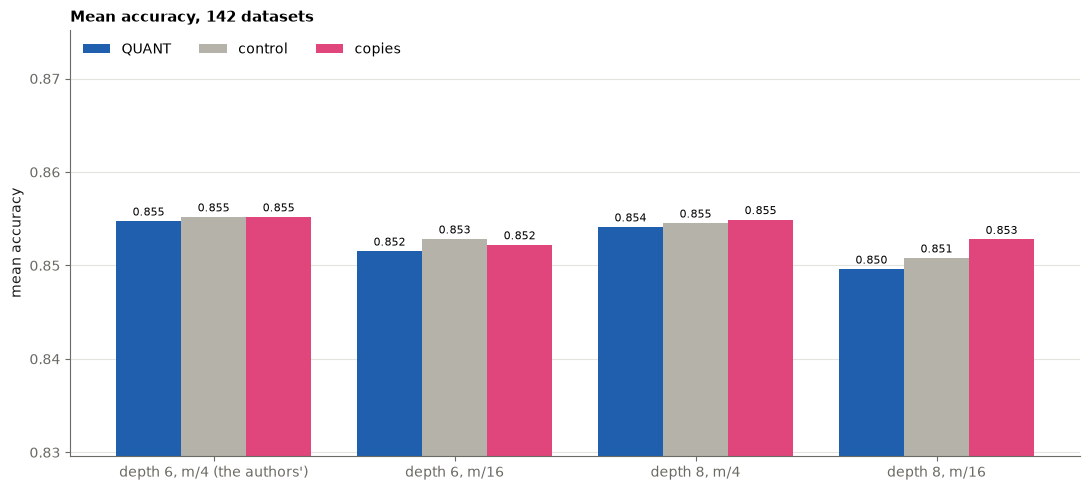

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(MEAN))
for k, c in enumerate(CLASSIFIERS):
    bars = ax.bar(x + (k - 1) * 0.27, [m[c].mean() for m in MEAN.values()], 0.27, color=CLF_COLORS[c], label=NAMES[c])
    ax.bar_label(bars, fmt="{:.3f}", padding=2, fontsize=8)
ax.set_xticks(x, [SETTINGS[s] for s in MEAN])
values = [m[c].mean() for m in MEAN.values() for c in CLASSIFIERS]
ax.set_ylim(min(values) - 0.02, min(1.0, max(values) + 0.02))
ax.set_ylabel("mean accuracy")
ax.set_title("Mean accuracy, 142 datasets", loc="left")
ax.legend(loc="upper left", frameon=False, ncol=3)
fig.tight_layout()
plt.show()

## 3. Per dataset

Copies against QUANT, one point per dataset, one panel per setting; above the diagonal
the copies are more accurate. The three largest changes are named.

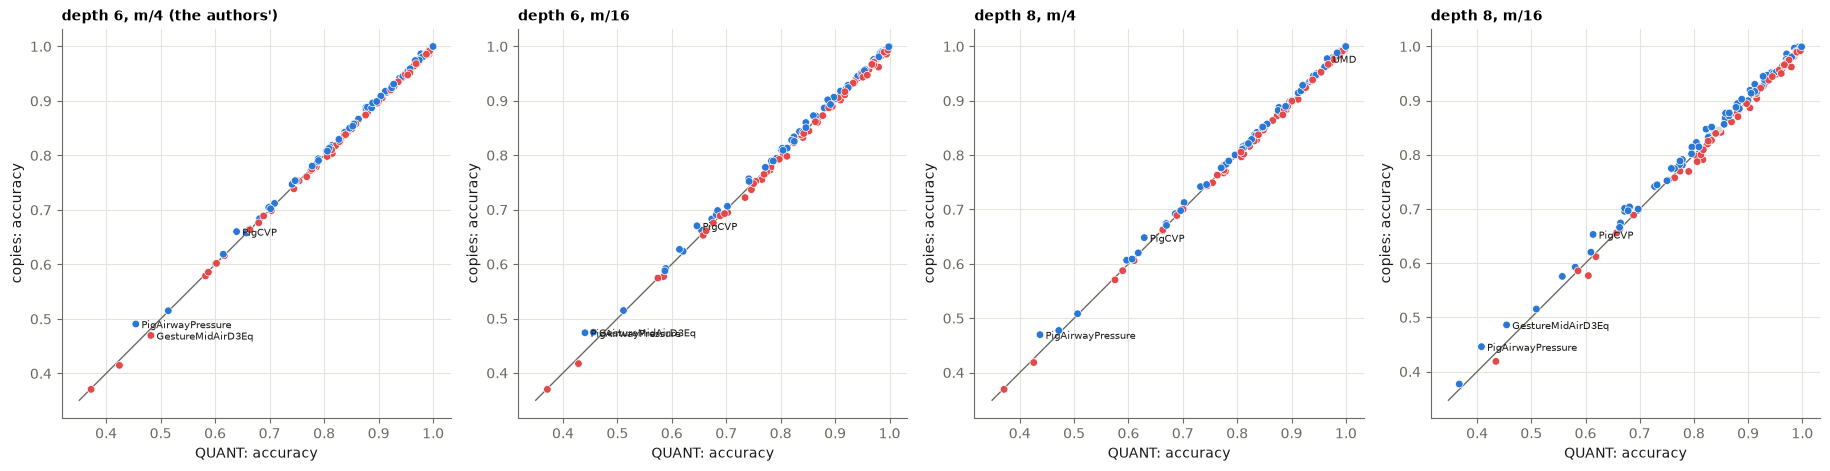

In [7]:
fig, axes = plt.subplots(1, len(MEAN), figsize=(4.6 * len(MEAN), 4.6), squeeze=False)
for ax, (s, m) in zip(axes[0], MEAN.items()):
    lo = min(m["extratrees"].min(), m["extratrees-dup"].min()) - 0.02
    ax.plot([lo, 1], [lo, 1], color=MUTED, linewidth=1, zorder=1)
    change = m["extratrees-dup"] - m["extratrees"]
    ax.scatter(m["extratrees"], m["extratrees-dup"], s=30, zorder=3, edgecolor="white", linewidth=0.5,
               c=[BETTER if d > 1e-12 else WORSE if d < -1e-12 else EQUAL for d in change])
    for name in change.abs().sort_values().index[-3:]:
        ax.annotate(name, (m.loc[name, "extratrees"], m.loc[name, "extratrees-dup"]), xytext=(4, -3),
                    textcoords="offset points", fontsize=7.5, color=TEXT)
    ax.set_xlabel("QUANT: accuracy")
    ax.set_ylabel("copies: accuracy")
    ax.set_title(SETTINGS[s], loc="left", fontsize=10)
    ax.set_aspect("equal")
    ax.grid(True, axis="both")
fig.tight_layout()
plt.show()

## 4. Long and short series

The weighting should matter most where QUANT makes many features, i.e. on long series. The effect of the weighting
(copies - control) on every dataset, one panel per setting, against its number of features at the authors' setting.

d6v4: copies - control, series of 500+ points (54): +0.0017, better/equal/worse 25/3/26; shorter (88): -0.0010, 30/5/53
d6v16: copies - control, series of 500+ points (54): +0.0015, better/equal/worse 23/2/29; shorter (88): -0.0019, 32/3/53
d8v4: copies - control, series of 500+ points (54): +0.0017, better/equal/worse 25/3/26; shorter (88): -0.0004, 44/3/41
d8v16: copies - control, series of 500+ points (54): +0.0039, better/equal/worse 35/2/17; shorter (88): +0.0008, 50/2/36


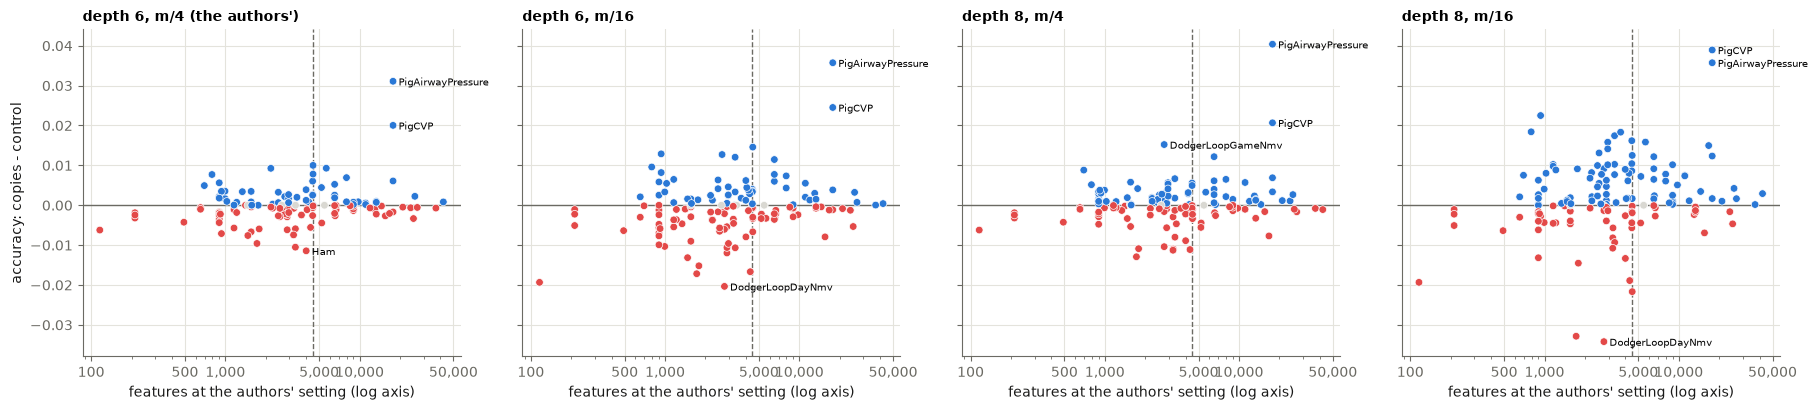

In [8]:
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

LONG_SERIES = 4469               
features = RUNS["d6v4"].groupby("dataset")["n_features"].first()
long = features[features >= LONG_SERIES].index
fig, axes = plt.subplots(1, len(MEAN), figsize=(4.6 * len(MEAN), 4.2), squeeze=False, sharey=True)
for ax, (s, m) in zip(axes[0], MEAN.items()):
    change = m["extratrees-dup"] - m["extratrees-k"]
    ax.scatter(features[change.index], change, s=30, zorder=3, edgecolor="white", linewidth=0.5,
               c=[BETTER if d > 1e-12 else WORSE if d < -1e-12 else EQUAL for d in change])
    for name in change.abs().sort_values().index[-3:]:
        ax.annotate(name, (features[name], change[name]), xytext=(4, -3), textcoords="offset points", fontsize=7.5)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axvline(LONG_SERIES, color=MUTED, linewidth=1, linestyle="--")
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(LogLocator(subs=[1, 5]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("features at the authors' setting (log axis)")
    ax.set_title(SETTINGS[s], loc="left", fontsize=10)
    ax.grid(True, axis="both")
    short = change.drop(long)
    print(f"{s}: copies - control, series of 500+ points ({len(long)}): {change[long].mean():+.4f}, better/equal/worse "
          f"{'/'.join(map(str, wdl_counts(change[long])))}; shorter ({len(short)}): {short.mean():+.4f}, "
          f"{'/'.join(map(str, wdl_counts(short)))}")
axes[0][0].set_ylabel("accuracy: copies - control")
fig.tight_layout()
plt.show()

## 5. Question 1: going deeper

The mean accuracy at depth 6 and depth 8 for each classifier, with m / 4 and with m / 16 quantiles per interval. If the
copies answer the question, QUANT's line falls with m / 16 and the copies' line does not.

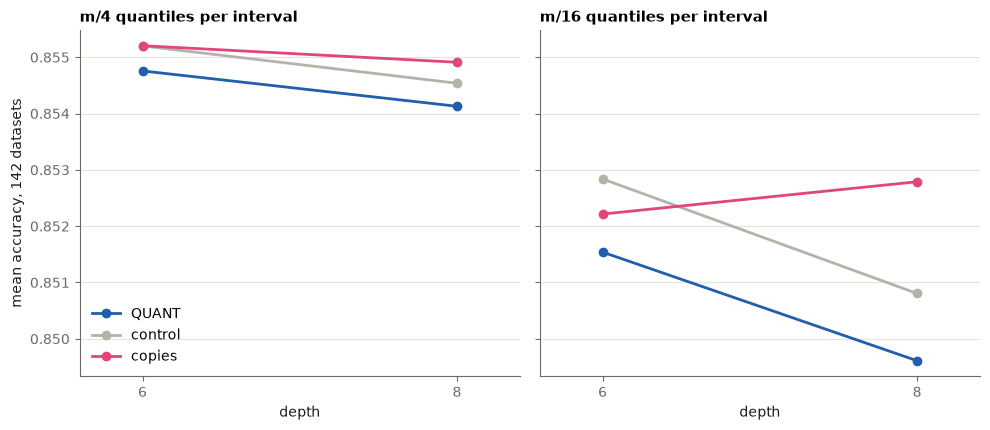

depth 6 depth 8   change better/equal/worse        p
m/4  QUANT    0.8548  0.8541  -0.0006           50/13/79    0.026
     control  0.8552  0.8545  -0.0007           49/14/79    0.015
     copies   0.8552  0.8549  -0.0003           55/14/73     0.12
m/16 QUANT    0.8515  0.8496  -0.0019           42/14/86  1.9e-05
     control  0.8528  0.8508  -0.0020           42/11/89  1.7e-05
     copies   0.8522  0.8528  +0.0006           65/13/64     0.76

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
rows = {}
for ax, (v, title) in zip(axes, [("4", "m/4 quantiles per interval"), ("16", "m/16 quantiles per interval")]):
    for c in CLASSIFIERS:
        values = [MEAN[f"d6v{v}"][c].mean(), MEAN[f"d8v{v}"][c].mean()]
        ax.plot([6, 8], values, marker="o", color=CLF_COLORS[c], linewidth=2, label=NAMES[c])
        r = compare(MEAN[f"d8v{v}"][c], MEAN[f"d6v{v}"][c])
        rows[(f"m/{v}", NAMES[c])] = {"depth 6": round(values[0], 4), "depth 8": round(values[1], 4),
                                      "change": f"{r['change']:+.4f}", "better/equal/worse": r["better/equal/worse"],
                                      "p": f"{r['p']:.2g}"}
    ax.set_xticks([6, 8])
    ax.set_xlim(5.6, 8.4)
    ax.set_xlabel("depth")
    ax.set_title(title, loc="left")
axes[0].set_ylabel("mean accuracy, 142 datasets")
axes[0].legend(loc="lower left", frameon=False)
fig.tight_layout()
plt.show()
pd.DataFrame(rows).T

## 6. Question 2: cheaper, and the time

Other settings against QUANT at its default (depth 6, m/4), and the time of the copies against QUANT's on the same
runs.

In [10]:
default = MEAN["d6v4"]["extratrees"]
rows = {}
for label, s, c in [("depth 6, m/4, control", "d6v4", "extratrees-k"), ("depth 6, m/4, copies", "d6v4", "extratrees-dup"),
                    ("depth 8, m/4, copies", "d8v4", "extratrees-dup"), ("depth 6, m/16, QUANT", "d6v16", "extratrees"),
                    ("depth 6, m/16, copies", "d6v16", "extratrees-dup"), ("depth 8, m/16, copies", "d8v16", "extratrees-dup")]:
    r = compare(MEAN[s][c], default)
    rows[label] = {"mean accuracy": round(MEAN[s][c].mean(), 4), "change": f"{r['change']:+.4f}",
                   "better/equal/worse": r["better/equal/worse"], "p": f"{r['p']:.2g}"}
print(f"QUANT's default: {default.mean():.4f}")
display(pd.DataFrame(rows).T)

times, total = {}, 0.0
for s, d in RUNS.items():
    transform = d.groupby(["dataset", "resample"])[["time_transform_train", "time_transform_test"]].first().sum().sum()
    fit_predict = d.groupby("classifier")["fit_predict"].sum()
    quant, copies = transform + fit_predict["extratrees"], transform + fit_predict["extratrees-dup"]
    total += transform + fit_predict.sum()
    times[SETTINGS[s]] = {"QUANT (hours)": round(quant / 3600, 2), "copies (hours)": round(copies / 3600, 2),
                          "extra time": f"{100 * (copies / quant - 1):+.0f}%",
                          "all three classifiers (hours)": round((transform + fit_predict.sum()) / 3600, 2)}
times = pd.DataFrame(times).T
print(f"measured time of the whole run: {total / 3600:.1f} hours")
times

QUANT's default: 0.8548


,mean accuracy,change,better/equal/worse,p
"depth 6, m/4, control",0.8552,+0.0004,81/9/52,0.016
"depth 6, m/4, copies",0.8552,+0.0004,62/6/74,0.98
"depth 8, m/4, copies",0.8549,+0.0002,60/8/74,0.61
"depth 6, m/16, QUANT",0.8515,-0.0032,49/6/87,1.1e-05
"depth 6, m/16, copies",0.8522,-0.0025,50/5/87,0.00046
"depth 8, m/16, copies",0.8528,-0.0020,42/5/95,6.2e-05


measured time of the whole run: 6.6 hours


,QUANT (hours),copies (hours),extra time,all three classifiers (hours)
"depth 6, m/4 (the authors')",0.64,0.71,+12%,1.47
"depth 6, m/16",0.45,0.49,+9%,0.8
"depth 8, m/4",1.15,1.41,+23%,2.71
"depth 8, m/16",0.79,1.07,+35%,1.67


## Conclusions

**The run:** 142 datasets x 30 resamples x 3 classifiers x 4 settings = 51,120 runs, all finished.

- **At the authors' setting (depth 6, m/4) the weighting changes nothing:** QUANT 0.8548, control 0.8552, copies 0.8552;
  copies - control 0.000 (better / equal / worse on 55 / 8 / 79 datasets, p = 0.18), copies - QUANT 0.000 (p = 0.98).
- **Where the small intervals dominate most (depth 8, m/16), the weighting helps, significantly:** copies 0.8528, control
  0.8508, QUANT 0.8496. Copies - control +0.002 (85 / 4 / 53 datasets, p = 0.002, Holm 0.009), copies - QUANT +0.003
  (80 / 6 / 56, p = 0.0009, Holm 0.004). The gain is larger on the 54 series of 500+ points (+0.004, 35 / 2 / 17) than on the 88 shorter ones (+0.001,
  50 / 2 / 36). In the other two settings copies - control is -0.001 and 0.000, not significant.
- **Question 1, deeper: with few quantiles, the weighting removes the loss at depth 8.** With m/16, QUANT falls from depth
  6 to depth 8 (-0.0019, worse on 86 of 142 datasets, p = 0.00002), as in the paper's Figure 8, and so does the control
  (-0.0020, p = 0.00002); the copies show no loss (+0.0006, 65 better and 64 worse, p = 0.76). The control has as many
  features per split as the copies, so the extra candidates do not explain it: drawing the larger intervals more often
  does, as the authors' explanation predicts. With m/4 all three lose a little (-0.0003 to -0.0007).
- **Question 2, cheaper: no.** With m/16 at depth 6 the accuracy stays below QUANT's default without copies (-0.0032,
  p = 0.00001) and with them (-0.0025, p = 0.0005). Depth 8 with m/16 and copies stays below it too (-0.0020,
  p = 0.00006).
- **No setting with copies beats QUANT's default:** the closest are depth 6 m/4 (+0.0004, p = 0.98) and depth 8 m/4
  (+0.0002, p = 0.61). The control at the authors' setting is the only result slightly above it (+0.0004, better on 81
  datasets, worse on 52, p = 0.016 before any correction): trying a few more features per split may help a little by
  itself, but this was not one of the questions tested here.
- **The time:** the copies take +12% at the authors' setting, +9% at depth 6 m/16, +23% at depth 8 m/4 and +35% at depth 8
  m/16.
- **The size:** the effects are 0.2 to 0.3 percentage points, in line with the paper's sensitivity analysis: QUANT's default
  is robust to these settings.

**In short:** drawing the larger intervals more often does not improve QUANT at its default setting, and no setting
with copies beats that default. But it does fix the weakness the authors describe: with few quantiles and deep levels, the
many small intervals crowd out the larger ones and accuracy falls; with the weighting it does not.